# 02 — Data engineering

Chargement, exploration, valeurs manquantes, nettoyage, pondérations, base SQL.
Le code réutilisable est dans `src/nutrihfr/pipeline.py`.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))   # pour importer le code de src/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from nutrihfr import config as C

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})
C.DOSSIER_FIGURES.mkdir(parents=True, exist_ok=True)
C.DOSSIER_TABLES.mkdir(parents=True, exist_ok=True)

## 1. Chargement

In [2]:
from nutrihfr.pipeline import ChargeurINCA3
individus, consommations, apports_anses = ChargeurINCA3().charger()
print(f"{len(individus)} adultes, {len(consommations):,} lignes de consommation, "
      f"{consommations['aliment_code_INCA3'].nunique()} aliments différents")
individus.head()

2121 adultes, 149,392 lignes de consommation, 2632 aliments différents


,NOIND,sexe,classe_age,age_approx,poids,taille,ponderation
0,110100101,Homme,18-44 ans,31,51.60,168.00,"20,743.86"
1,110100701,Femme,45-64 ans,55,65.10,166.00,"6,559.19"
2,110100801,Homme,45-64 ans,55,78.60,162.00,"11,348.46"
3,110101201,Homme,45-64 ans,55,81.90,177.00,"2,783.30"
4,110101401,Femme,65-79 ans,72,51.80,152.00,"5,051.06"


In [3]:
consommations[["NOIND", "R24_num", "groupe", "aliment_libelle_INCA3", "qte_conso", "qte_conso_pond", "aet", "calcium"]].head()

,NOIND,R24_num,groupe,aliment_libelle_INCA3,qte_conso,qte_conso_pond,aet,calcium
0,110100101,1,Eau du robinet,eau (du robinet),147.50,147.50,0.00,7.13
1,110100101,1,Jus de fruits et de légumes,jus de fruits 100% pur jus,500.00,500.00,45.00,0.41
2,110100101,1,Matières grasses animales,matière grasse de cuisson n.s.,3.22,3.22,0.00,0.00
3,110100101,1,Pommes de terre et tubercules,frite (de pommes de terre) à la friteuse,107.00,107.00,267.00,23.80
4,110100101,1,Plats à base de viandes,nugget de poulet,161.00,161.00,234.00,11.00


Points importants (notice INCA 3) :
- `qte_conso` est la quantité consommée en grammes ; `qte_conso_pond` est cette quantité multipliée par `R24_pond`, qui rééquilibre jours de semaine et de week-end ;
- les colonnes nutriments (`aet`, `proteines`, `calcium`…) donnent la composition **pour 100 g** de l'aliment consommé ;
- l'âge exact n'est pas diffusé : on dispose seulement de 3 classes (18-44, 45-64, 65-79 ans).

## 2. Exploration

In [4]:
display(pd.crosstab(individus["sexe"], individus["classe_age"], margins=True))
individus[["poids", "taille", "ponderation"]].describe().T

classe_age,18-44 ans,45-64 ans,65-79 ans,All
sexe,,,,
Femme,459,481,294,1234
Homme,324,346,217,887
All,783,827,511,2121


,count,mean,std,min,25%,50%,75%,max
poids,"2,116.00",72.67,15.47,40.00,61.57,70.65,82.00,161.10
taille,"2,121.00",167.76,9.30,143.00,160.00,167.00,175.00,196.00
ponderation,"2,121.00","21,188.76","24,156.69","1,003.66","7,421.42","13,967.74","25,714.45","259,666.39"


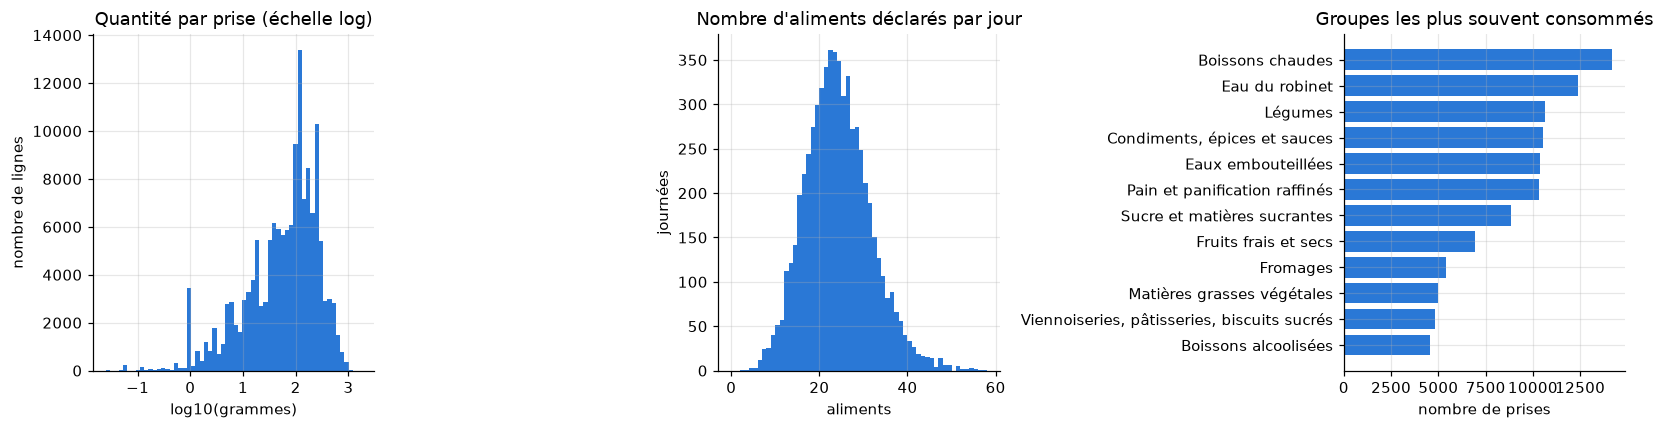

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(np.log10(consommations["qte_conso"]), bins=60, color=C.PALETTE[0])
axes[0].set(title="Quantité par prise (échelle log)", xlabel="log10(grammes)", ylabel="nombre de lignes")

par_jour = consommations.groupby(["NOIND", "R24_num"]).size()
axes[1].hist(par_jour, bins=range(0, par_jour.max() + 2), color=C.PALETTE[0])
axes[1].set(title="Nombre d'aliments déclarés par jour", xlabel="aliments", ylabel="journées")

top = consommations["groupe"].value_counts().head(12).sort_values()
axes[2].barh(top.index, top.values, color=C.PALETTE[0])
axes[2].set(title="Groupes les plus souvent consommés", xlabel="nombre de prises")

plt.tight_layout()
plt.savefig(C.DOSSIER_FIGURES / "02_exploration.png", bbox_inches="tight")
plt.show()

## 3. Valeurs manquantes

In [6]:
manquants = pd.concat([individus.isna().sum(), consommations.isna().sum()])
manquants[manquants > 0].rename("nb manquants").to_frame()

,nb manquants
poids,5
aet,10
proteines,10
glucides,10
fibres,10
lipides,10
alcool,10
calcium,10
fer,10
vitamine_c,10


Il y a très peu de valeurs manquantes. Choix retenus (sans imputation) :
- **poids corporel manquant** (5 adultes) : l'individu est gardé, mais on ne peut pas tester s'il sous-déclare (critère de Goldberg, notebook 04) ;
- **composition manquante** (10 lignes) : la ligne ne compte pas dans l'apport (c'est aussi ce que fait l'Anses, puisque nos apports recalculés sont identiques aux siens).

## 4. Nettoyage

Les contrôles du notebook 03 ne trouvent ni doublon, ni quantité négative ou nulle, ni aliment inconnu, ni quantité implausible (maximum : 1,8 kg de bière en une prise). **Aucune ligne n'est supprimée** : les données INCA 3 sont déjà nettoyées par l'Anses. Le seul « nettoyage » est la sélection de la population (adultes Pop3), faite par `ChargeurINCA3`.

## 5. Représentativité et pondérations

Les participants ne ressemblent pas exactement à la population française (certains profils répondent moins). La pondération `ponderation` (`pond_indiv_adu_pop3`) corrige ces écarts : **toutes les moyennes et tous les percentiles du projet sont pondérés.**

In [7]:
w = individus["ponderation"]
print(f"Population représentée : {w.sum():,.0f} adultes")
print(f"Taille d'échantillon effective (Kish) : {w.sum()**2 / (w**2).sum():.0f} sur {len(w)}")

structure = individus.groupby(["sexe", "classe_age"]).agg(n=("NOIND", "size"), poids=("ponderation", "sum"))
structure["% échantillon"] = 100 * structure["n"] / structure["n"].sum()
structure["% population (pondéré)"] = 100 * structure["poids"] / structure["poids"].sum()
structure[["% échantillon", "% population (pondéré)"]]

Population représentée : 44,941,366 adultes
Taille d'échantillon effective (Kish) : 923 sur 2121


% échantillon  % population (pondéré)
sexe  classe_age                                       
Femme 18-44 ans           21.64                   23.25
      45-64 ans           22.68                   18.79
      65-79 ans           13.86                    9.47
Homme 18-44 ans           15.28                   22.65
      45-64 ans           16.31                   17.74
      65-79 ans           10.23                    8.09

Lecture : sans pondération, les femmes seraient sur-représentées (58 % de l'échantillon). La taille effective de Kish mesure la perte de précision due à la dispersion des poids.

## 6. Modèle relationnel et base SQLite

```
individus 1──n journees 1──n consommations n──1 aliments
                                  │
                                  1──n composition n──1 nutriments
individus 1──n apports n──1 nutriments
```

- `individus` : un adulte (sexe, classe d'âge, poids, taille, pondération)
- `journees` : un jour de rappel d'un individu (avec son poids semaine / week-end)
- `consommations` : un aliment consommé (quantité)
- `composition` : teneur pour 100 g de chaque nutriment, **pour chaque ligne** (dans INCA 3, la composition dépend de la description précise de l'aliment)
- `aliments`, `nutriments` : tables de référence
- `apports` : résultat du calcul, apport journalier par individu et nutriment

Le schéma est dans `sql/schema.sql`.

In [8]:
from nutrihfr.pipeline import CalculApports, creer_base_sqlite
apports = CalculApports(consommations, individus).par_individu()
creer_base_sqlite(individus, consommations, apports)

{'individus': 2121,
 'journees': 6283,
 'aliments': 2632,
 'nutriments': 9,
 'consommations': 149392,
 'composition': 1344438,
 'apports': 19089}

Exemple de requête : apport moyen **pondéré** en calcium par sexe, directement en SQL.

In [9]:
import sqlite3
requete = """
SELECT i.sexe,
       COUNT(*) AS n,
       ROUND(SUM(a.valeur_par_jour * i.ponderation) / SUM(i.ponderation), 0) AS calcium_moyen_mg
FROM apports a
JOIN individus i ON i.id_indiv = a.id_indiv
WHERE a.code_nutriment = 'calcium'
GROUP BY i.sexe
"""
with sqlite3.connect(C.BASE_SQLITE) as con:
    display(pd.read_sql(requete, con))
    print("Violations de clés étrangères :", con.execute("PRAGMA foreign_key_check").fetchall())

,sexe,n,calcium_moyen_mg
0,Femme,1234,840.00
1,Homme,887,"1,024.00"


Violations de clés étrangères : []


## 7. Confidentialité (RGPD)

Les données sont **pseudonymisées** (un numéro `NOIND` à la place de l'identité, âge en classes), mais restent des données de santé personnelles. Précautions prises :
- les fichiers de données ne sont **pas mis sur GitHub** (`data/` est dans le `.gitignore`) ;
- on ne publie que des résultats **agrégés** (moyennes, pourcentages), jamais de ligne individuelle.

## 8. Biais

| Biais | Explication | Ce qu'on fait |
|---|---|---|
| Sélection (non-réponse) | les participants ne sont pas représentatifs | pondérations |
| Sous-déclaration | on oublie ou minimise certains aliments | critère de Goldberg (notebook 04) |
| Peu de jours observés | 2-3 jours ne reflètent pas l'alimentation habituelle | on le signale pour les percentiles (Q6) |

➡️ Suite : `03_qualite.ipynb`